In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np

import ncar_jobqueue
from dask.distributed import Client

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy import stats
import pop_tools 
import pandas as pd
import cftime
import matplotlib.colors as colors
import utils

### Let's looks at temperature in the Caribbean during Medieval Warm Period 

### first let's figure out how to trim the data in x and y

In [2]:
var = 'SST'
case = 'b.e11.BLMTRC5CN.f19_g16.001'

In [3]:
path='/glade/campaign/cesm/collections/cesmLME/CESM-CAM5-LME/ocn/proc/tseries/monthly/' + var

In [4]:
files = sorted(glob(f'{path}/{case}.pop.h.{var}.085001-089912.nc'))       
ds = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, concat_dim="time", combine='nested',
                   drop_variables=["transport_components", "transport_regions"], decode_times=True)

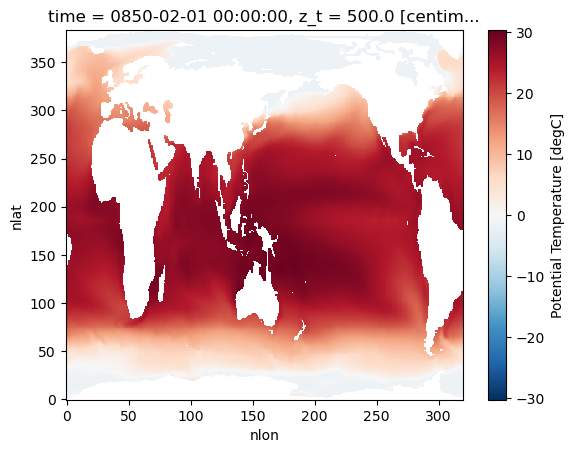

In [5]:
ds.SST.isel(time=0).plot()

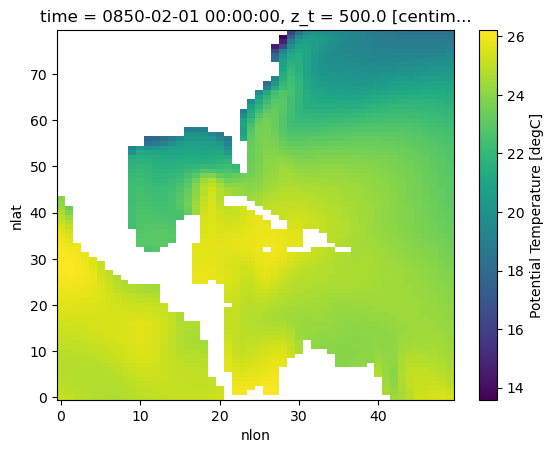

In [6]:
ds.SST.isel(time=0,nlon=slice(260,310),nlat=slice(220,300)).plot()

### Read in ensemble members with preprocess clipping

In [7]:
def preprocess(ds):
    ds=ds.isel(nlon=slice(260,310),nlat=slice(220,300))
    return ds

In [8]:
ens_mems = ['001','002','003','004','005','006','007','008','009','010','011','012','013']

In [9]:
ds = xr.Dataset()

var = 'SST'
path='/glade/campaign/cesm/collections/cesmLME/CESM-CAM5-LME/ocn/proc/tseries/monthly/' + var

for m in ens_mems:
    print(m)

    case = 'b.e11.BLMTRC5CN.f19_g16.' + m

    files = sorted(glob(f'{path}/{case}.pop.h.{var}.??????-??????.nc'))       
    ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, concat_dim="time", combine='nested',
                       drop_variables=["transport_components", "transport_regions"], decode_times=True,preprocess=preprocess)
    
    ds_tmp["time"] = ds_tmp.time_bound.compute().mean(dim="d2")
    
    ds = xr.concat([ds,ds_tmp], dim='member_id')

001
002
003
004
005
006
007
008
009
010
011
012
013


In [10]:
ds_mean = ds.mean(dim='member_id')

In [11]:
ds.time

<xarray.DataArray 'time' (time: 13873)>
array([cftime.DatetimeNoLeap(850, 1, 17, 0, 30, 0, 1, has_year_zero=True),
       cftime.DatetimeNoLeap(850, 2, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(850, 3, 16, 12, 0, 0, 0, has_year_zero=True), ...,
       cftime.DatetimeNoLeap(2005, 10, 16, 12, 0, 0, 2, has_year_zero=True),
       cftime.DatetimeNoLeap(2005, 11, 16, 0, 0, 0, 2, has_year_zero=True),
       cftime.DatetimeNoLeap(2005, 12, 16, 12, 0, 0, 2, has_year_zero=True)],
      dtype=object)
Coordinates:
  * time     (time) object 0850-01-17 00:30:00.000001 ... 2005-12-16 12:00:00...

### First compute annual means

In [12]:
ds_ann = ds.resample({'time':'A'}).mean(dim='time').compute()

In [13]:
ds_ann = ds_ann.squeeze()

In [14]:
ds_grid = pop_tools.get_grid('POP_gx1v7').isel(nlon=slice(260,310),nlat=slice(220,300))
lons=ds_grid.TLONG
lats=ds_grid.TLAT
area=ds_grid.TAREA
area_m=ds_grid.TAREA * 1e-4
lons_norm = utils.normal_lons(lons)

### Make a timeseries over the Puerto Rico region

In [15]:
box1_latmin = 17
box1_latmax = 19
box1_lonmin = -68.
box1_lonmax = -65.

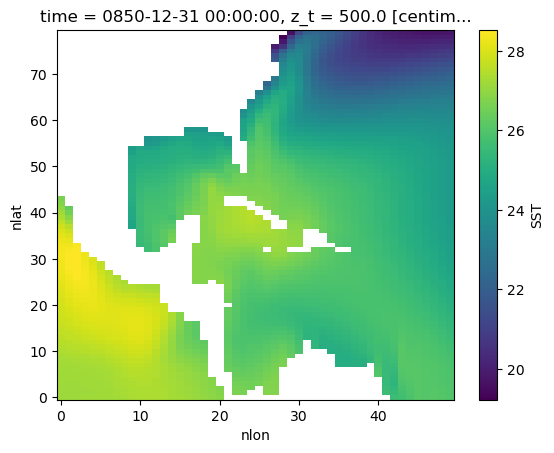

In [16]:
ds_ann.SST.isel(time=0,member_id=6).plot()

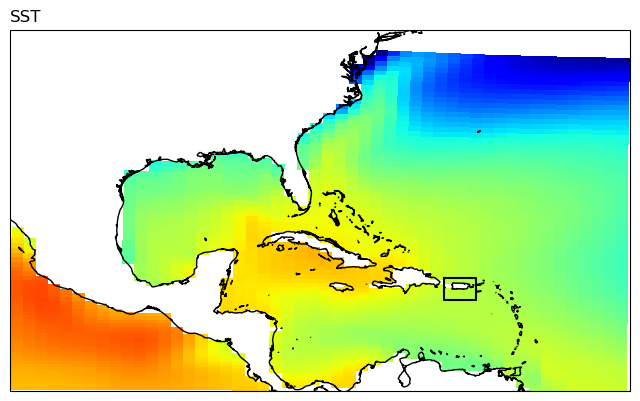

In [17]:
fig = plt.figure(figsize=(8,6))

ts=0

###############
ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())
#ax.set_extent([-110, -70, 5, 35], ccrs.PlateCarree())

ax.set_title('SST', loc='left')

#lon,lat,field = utils.adjust_pop_grid(lons, lats, ds_ann.SST.isel(time=ts))

pc = ax.pcolormesh(lons, lats, ds_ann.SST.isel(time=ts,member_id=7),
                    transform=ccrs.PlateCarree(),cmap='jet',
                   vmin=20,vmax=30)
ax.coastlines('10m',linewidth=1)

lon_pts = [box1_lonmin,box1_lonmax,box1_lonmax,box1_lonmin,box1_lonmin]
lat_pts = [box1_latmax,box1_latmax,box1_latmin,box1_latmin,box1_latmax]
ax.plot(lon_pts, lat_pts, color="black", linewidth=1.5,transform=ccrs.PlateCarree())

In [18]:
ensmean_SST = ds_ann.SST.mean(dim='member_id')

In [19]:
ones = np.full((80,50),1,dtype=int)
ones = xr.DataArray(ones,dims=('nlat','nlon'))
ones = ones.where(ds_grid.REGION_MASK>0)

mask = ones.where(lats<box1_latmax).where(lats>box1_latmin).where(lons_norm<box1_lonmax).where(lons_norm>box1_lonmin)

ts_box1 = xr.Dataset()

for var in ['SST']:
    print(var)
    masked_da = ds_ann[var].where(mask==1)
    masked_area = area.where(mask==1)
    ts_box1[var] = (masked_da * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
    
    ts_ens_mean = ts_box1[var].mean(dim='member_id')

SST


### DASK

In [20]:
def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=1,
        memory='25GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=25GB',
        project='NCGD0011',
        walltime='03:00:00',
        interface='ib0',)

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

In [21]:
cluster, client = get_ClusterClient()
cluster.scale(12) 
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.12.206.59:38651,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [22]:
ts_ens_mean['time'] = np.arange(850,2006,1)

CPU times: user 23.2 ms, sys: 5.92 ms, total: 29.1 ms
Wall time: 47.1 ms


[Text(0, 0.5, 'SST'), Text(0.5, 0, 'Year')]

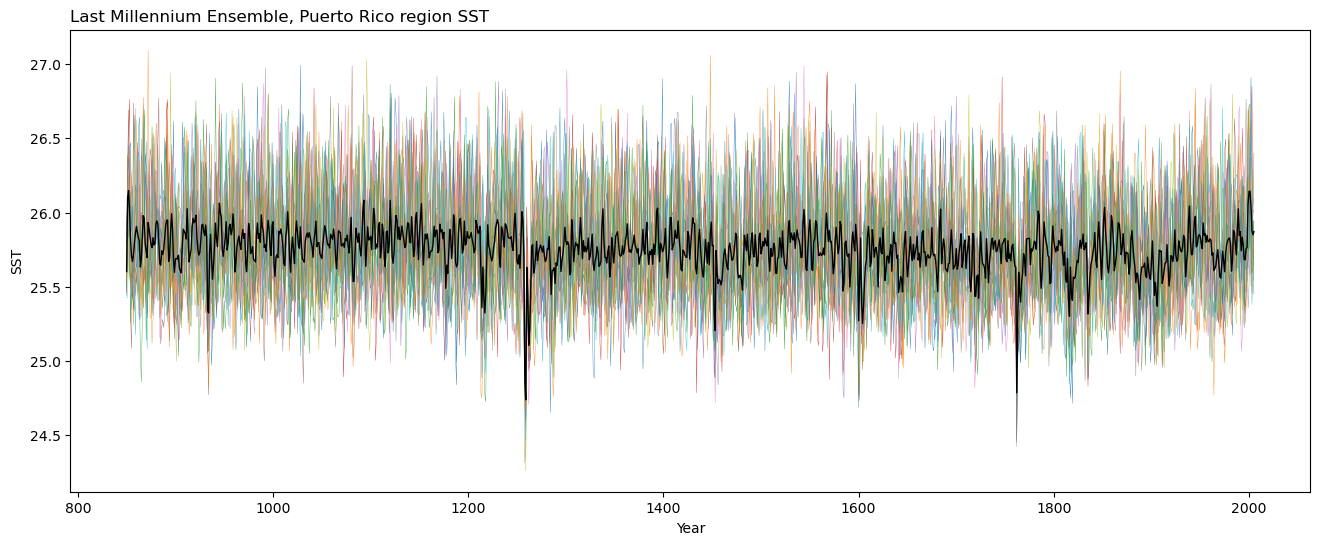

In [23]:
%%time

fig = plt.figure(figsize=(16,6))

ax = fig.add_subplot(1,1,1)
ax.set_title('Last Millennium Ensemble, Puerto Rico region SST', loc='left')


for mem in np.arange(0,13,1):
    #print(mem)
    ax.plot(ts_ens_mean['time'], ts_box1[var].isel(member_id=mem),linewidth=0.25)
    
ax.plot(ts_ens_mean['time'], ts_ens_mean,linewidth=1, color='black')
ax.set(ylabel=var,xlabel='Year');

### Compute climatology and then make a timeseries of the warmest month

##### (this takes awhile, so only run once)

In [24]:
ds_clim = ds_mean.groupby('time.month').mean('time').squeeze()

In [25]:
ts_clim = xr.Dataset()

for var in ['SST']:
    print(var)
    masked_da = ds_clim[var].where(mask==1)
    masked_area = area.where(mask==1)
    ts_clim[var] = (masked_da * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
    ts_clim[var].load()

SST


CPU times: user 11.4 ms, sys: 846 µs, total: 12.3 ms
Wall time: 13.2 ms


[Text(0, 0.5, 'SST'), Text(0.5, 0, 'Year')]

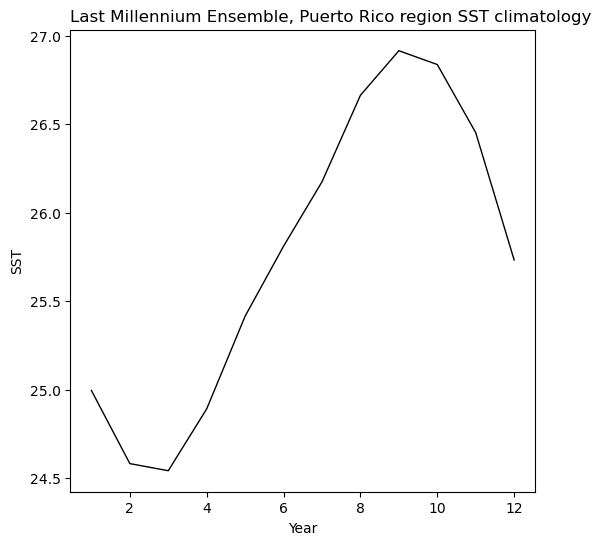

In [26]:
%%time

fig = plt.figure(figsize=(6,6))

ax = fig.add_subplot(1,1,1)
ax.set_title('Last Millennium Ensemble, Puerto Rico region SST climatology', loc='left')
    
ax.plot(np.arange(1,13,1), ts_clim['SST'],linewidth=1, color='black')

ax.set(ylabel=var,xlabel='Year');

In [27]:
ds_sept = ds.sel(time = np.in1d(ds['time.month'], 9))

(array([2.000000e+01, 3.100000e+02, 6.450000e+03, 4.979100e+04,
        1.664980e+05, 5.023080e+05, 1.127119e+06, 8.619170e+05,
        5.056310e+05, 6.646400e+04]),
 array([21.548748, 22.411182, 23.273617, 24.136053, 24.998487, 25.860922,
        26.723356, 27.58579 , 28.448227, 29.310661, 30.173096],
       dtype=float32),
 <BarContainer object of 10 artists>)

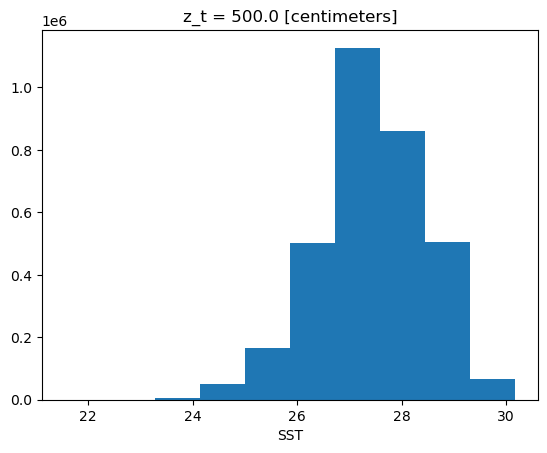

In [28]:
ds_sept.SST.mean(dim='member_id').plot()

### Make a timeseries around Puerto Rico for the month of September

In [29]:
ones = np.full((80,50),1,dtype=int)
ones = xr.DataArray(ones,dims=('nlat','nlon'))
ones = ones.where(ds_grid.REGION_MASK>0)

mask = ones.where(lats<box1_latmax).where(lats>box1_latmin).where(lons_norm<box1_lonmax).where(lons_norm>box1_lonmin)

ts_sept = xr.Dataset()

for var in ['SST']:
    print(var)
    masked_da = ds_sept[var].where(mask==1)
    masked_area = area.where(mask==1)
    ts_sept[var] = (masked_da * masked_area).sum(dim=('nlon','nlat')) / masked_area.sum(dim=('nlon','nlat'))
    
    ts_sept_ens_mean = ts_sept[var].mean(dim='member_id')

SST


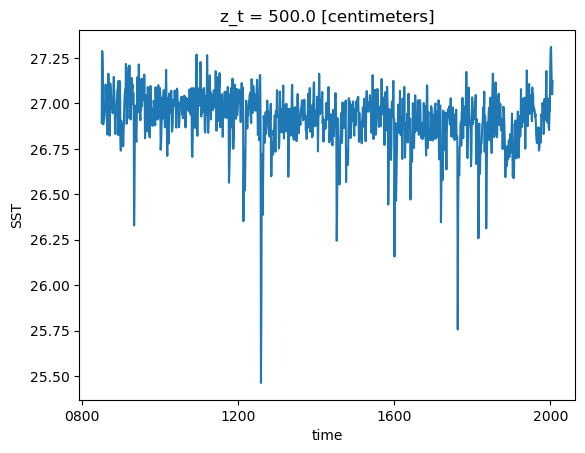

In [30]:
ts_sept_ens_mean.plot()

CPU times: user 5.92 s, sys: 487 ms, total: 6.41 s
Wall time: 1min 39s


[Text(0, 0.5, 'SST'), Text(0.5, 0, 'Year')]

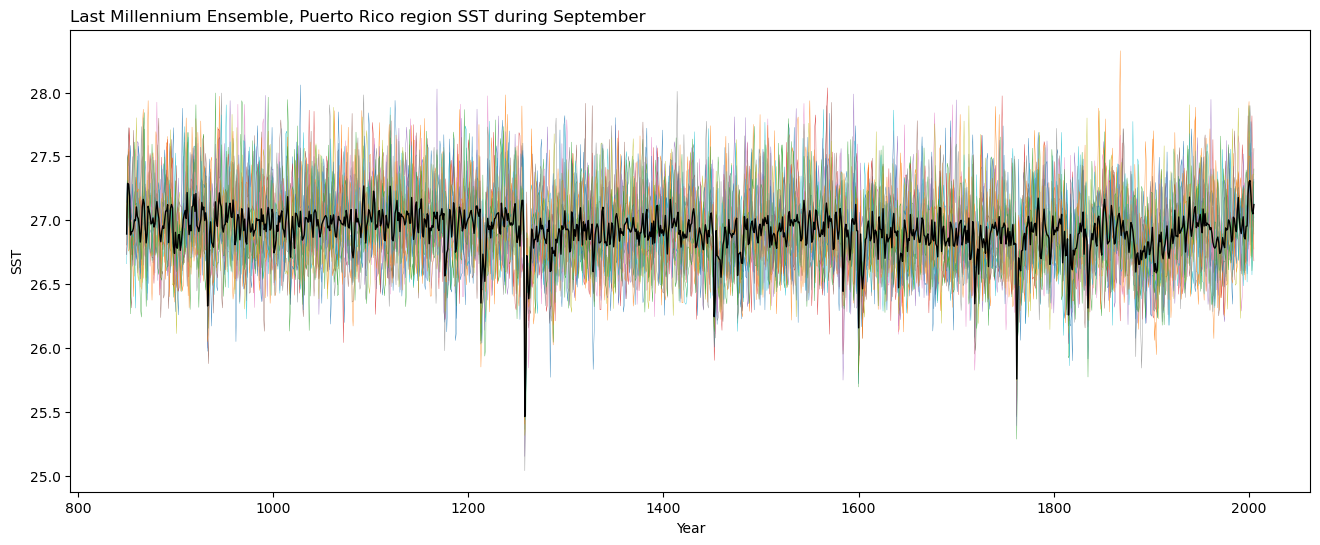

In [31]:
%%time

fig = plt.figure(figsize=(16,6))

ax = fig.add_subplot(1,1,1)
ax.set_title('Last Millennium Ensemble, Puerto Rico region SST during September', loc='left')

var ='SST'
for mem in np.arange(0,13,1):
    #print(mem)
    ax.plot(ts_ens_mean['time'], ts_sept[var].isel(member_id=mem),linewidth=0.25)
    
ax.plot(ts_ens_mean['time'], ts_sept_ens_mean,linewidth=1, color='black')
ax.set(ylabel=var,xlabel='Year');

### Make a mean over the whole thing and look at anomalies on a map, each 50 years

In [32]:
ds_ann_ensmean = ds_ann.mean(dim='member_id')

In [33]:
ds_sept_ensmean = ds_sept.mean(dim='member_id')

1. make a time mean over the ensemble means of the annual mean ds (ds_ann) and september ds (ts_sept_ens_mean)
2. subtract mean from the original ds' to create anomalies
3. plot anomalies in the Caribbean region every 50 years

In [34]:
mean_SST_ann = ds_ann_ensmean['SST'].mean(dim='time')
mean_SST_sept = ds_sept_ensmean['SST'].mean(dim='time')

In [35]:
SST_anoms_ann = ds_ann_ensmean.SST - mean_SST_ann
SST_anoms_sept = ds_sept_ensmean.SST - mean_SST_sept

In [36]:
SST_anoms_ann['time'] = np.arange(850,2006,1)
SST_anoms_sept['time'] = np.arange(850,2006,1)

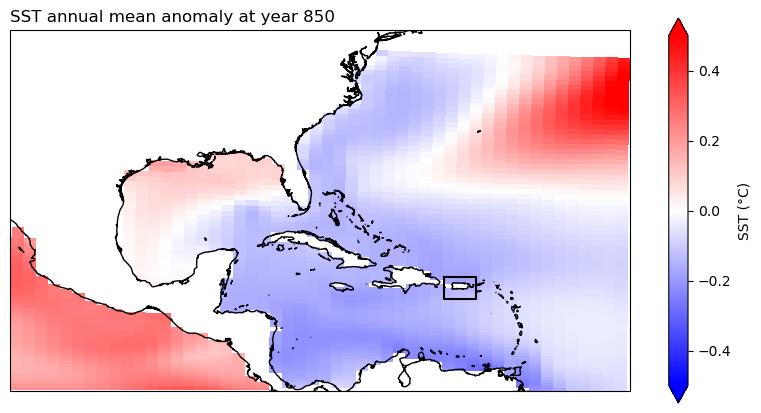

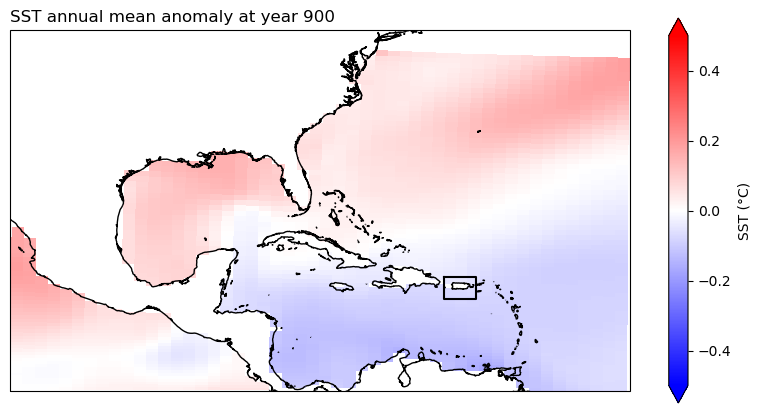

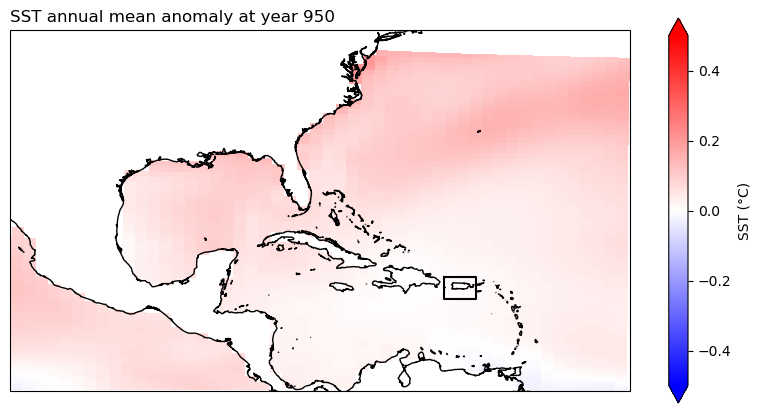

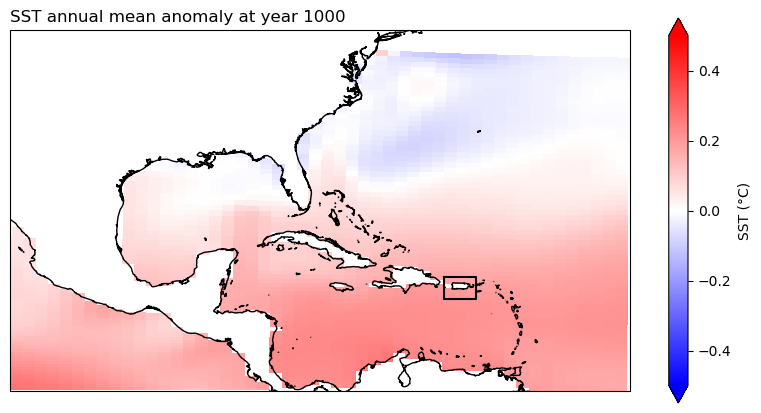

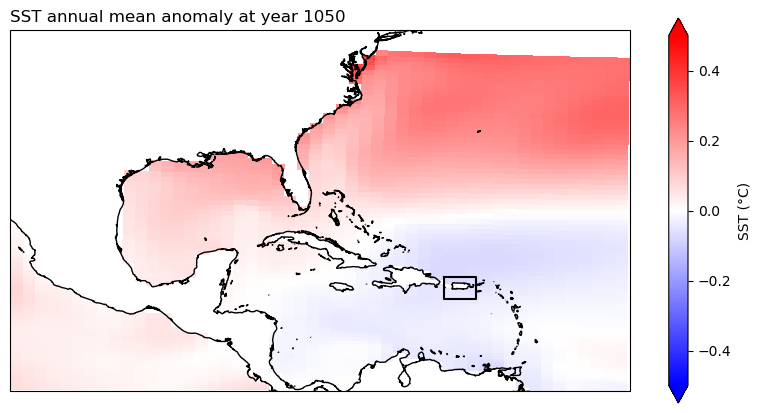

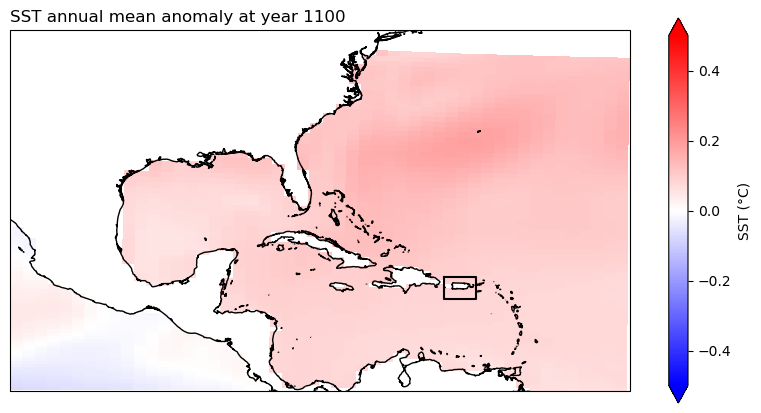

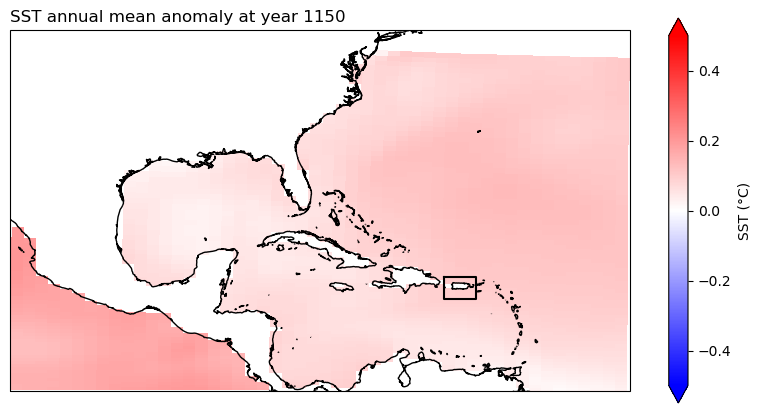

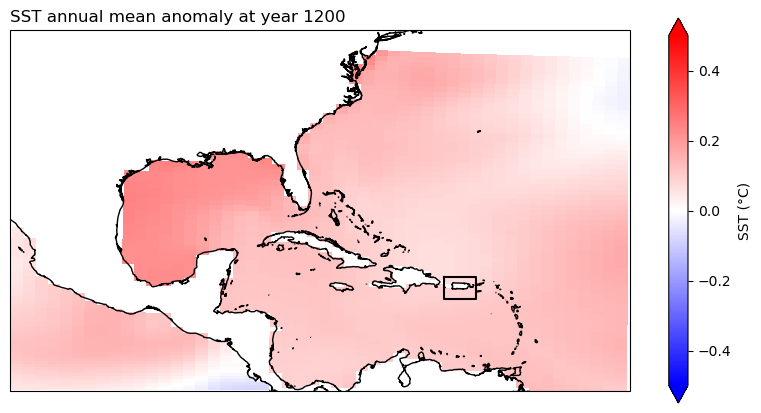

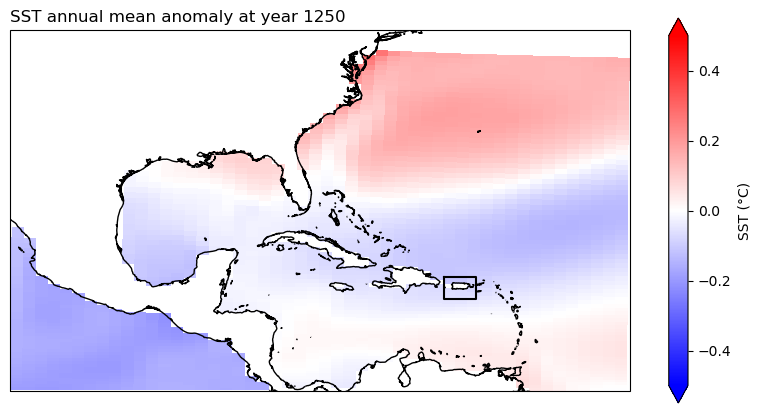

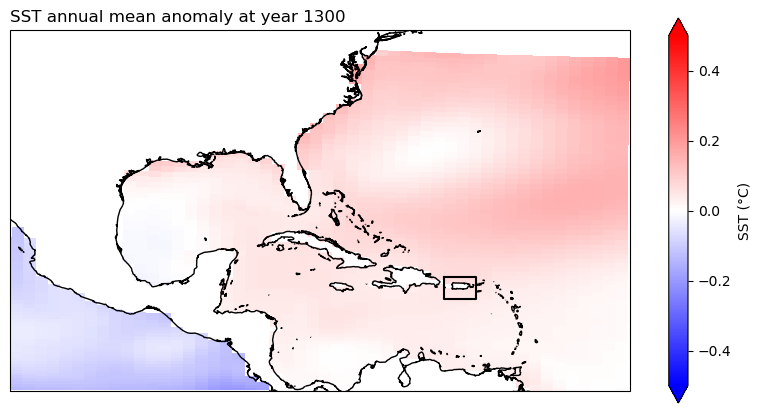

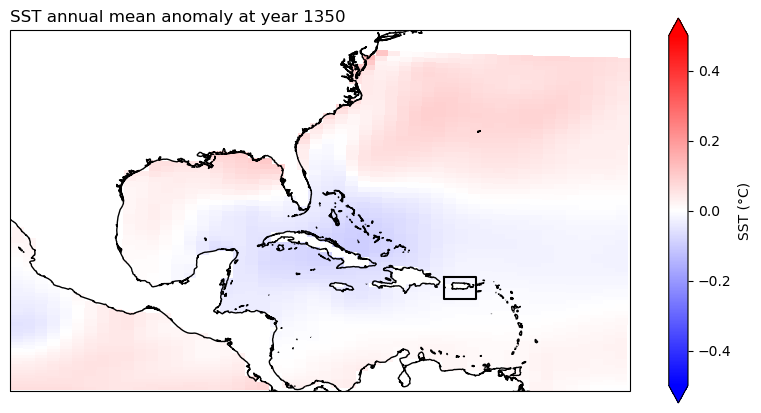

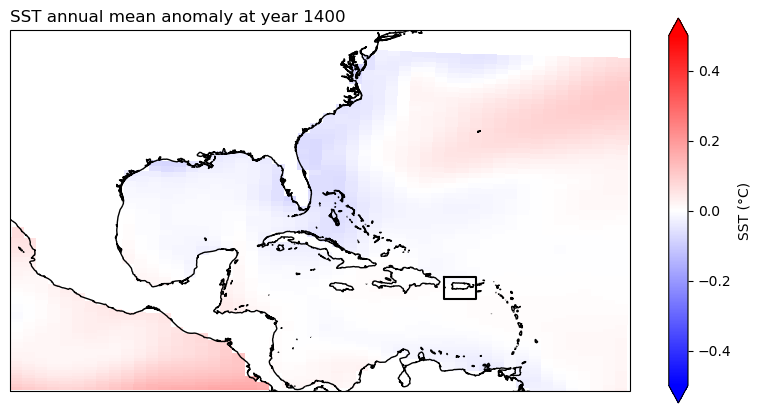

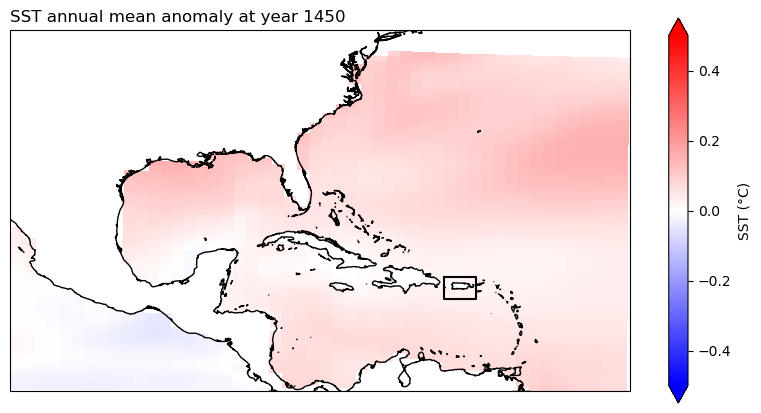

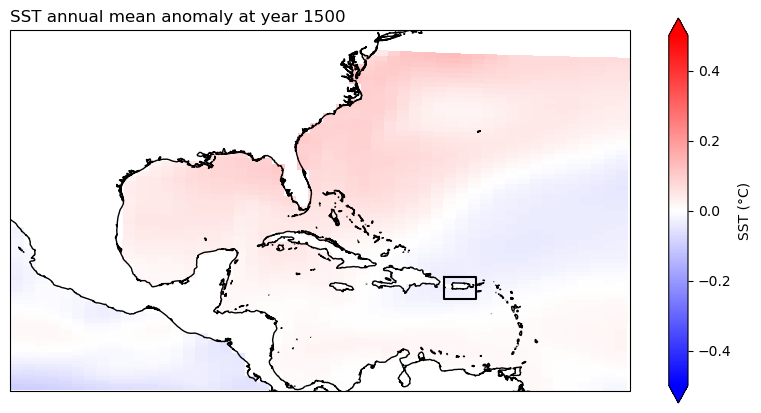

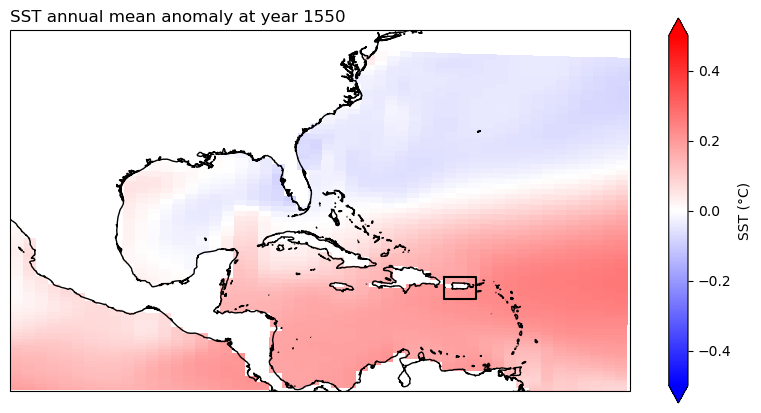

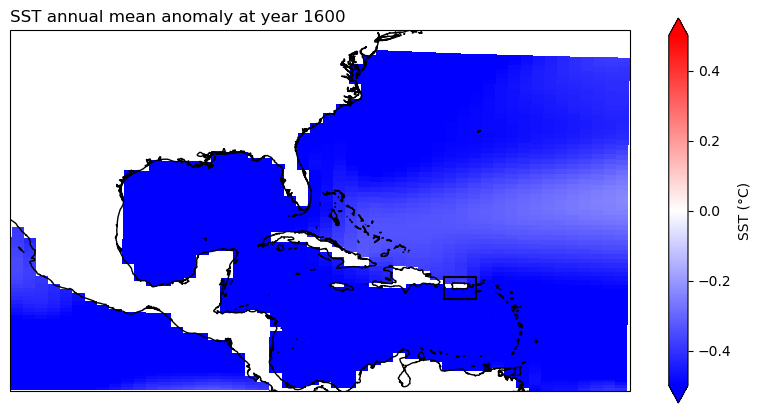

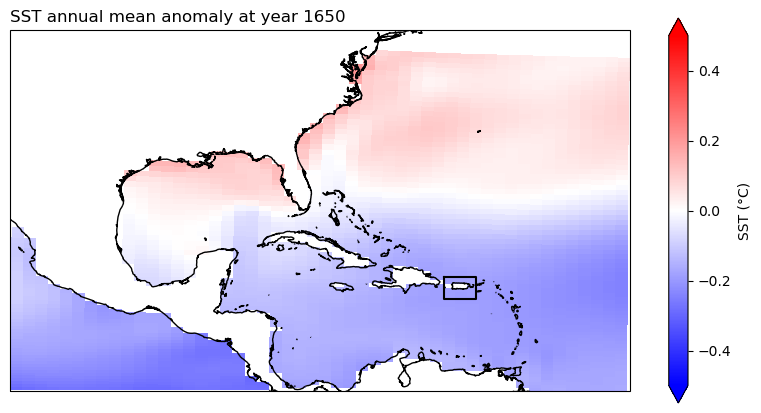

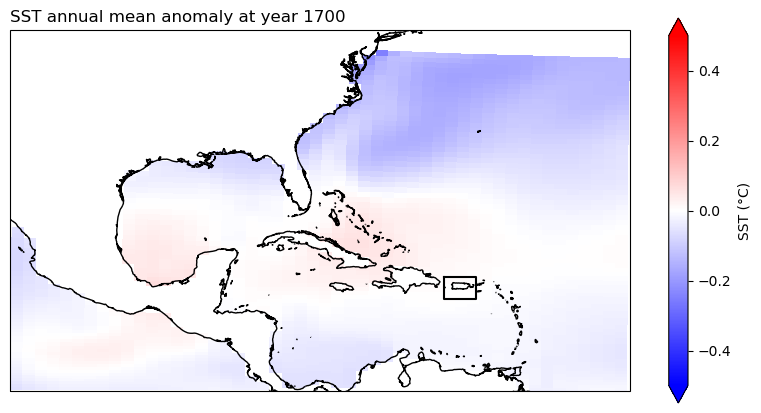

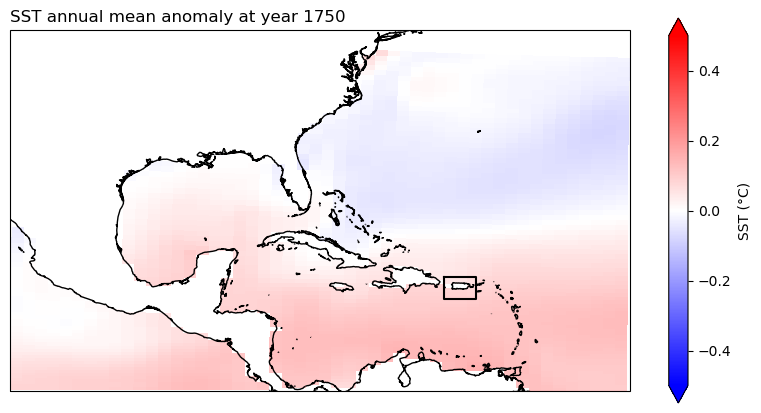

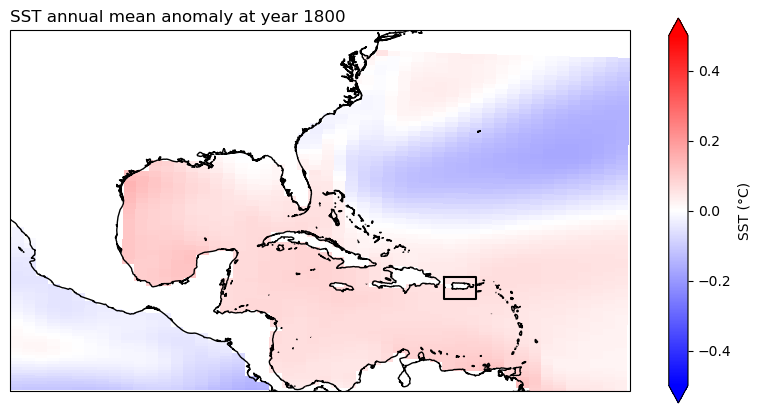

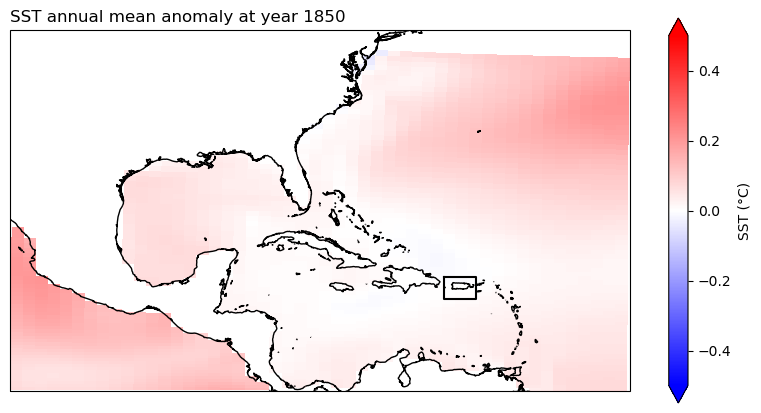

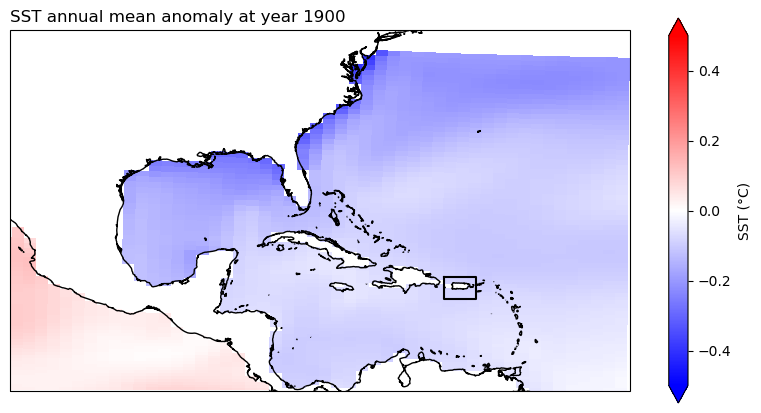

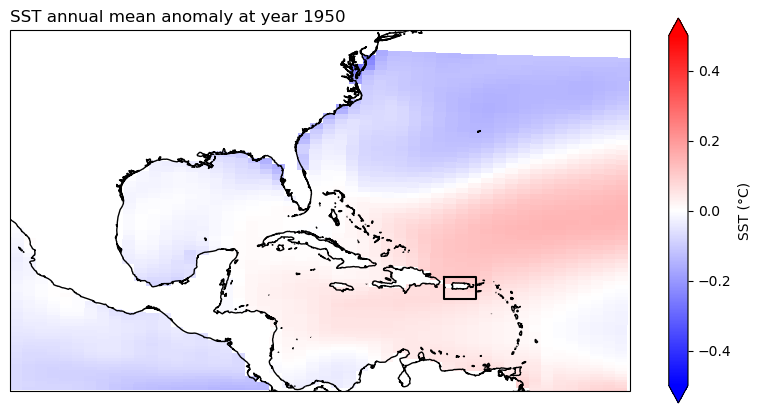

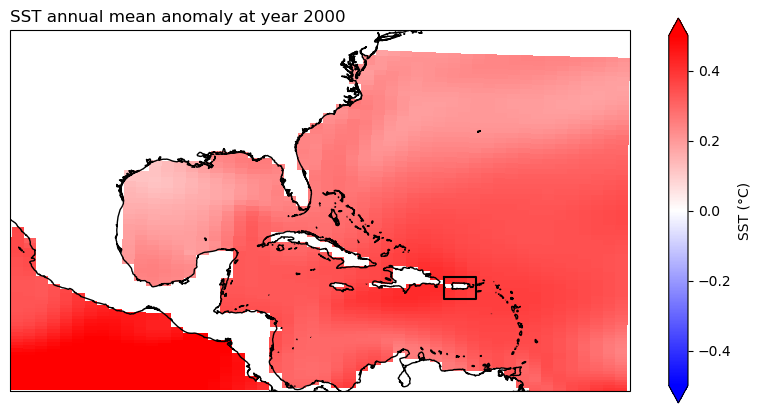

In [37]:
for year in np.arange(850,2001,50):

    fig = plt.figure(figsize=(10,5))

    ###############
    ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())

    ax.set_title('SST annual mean anomaly at year '+str(year), loc='left')

    #lon,lat,field = utils.adjust_pop_grid(lons, lats, ds_ann.SST.isel(time=ts))

    pc = ax.pcolormesh(lons, lats, SST_anoms_ann.sel(time=year),
                        transform=ccrs.PlateCarree(),cmap='bwr',
                       vmin=-0.5,vmax=0.5)
    ax.coastlines('10m',linewidth=1)

    lon_pts = [box1_lonmin,box1_lonmax,box1_lonmax,box1_lonmin,box1_lonmin]
    lat_pts = [box1_latmax,box1_latmax,box1_latmin,box1_latmin,box1_latmax]
    ax.plot(lon_pts, lat_pts, color="black", linewidth=1.5,transform=ccrs.PlateCarree())

    fig.colorbar(pc, label='SST (°C)',extend='both');

## September anomalies

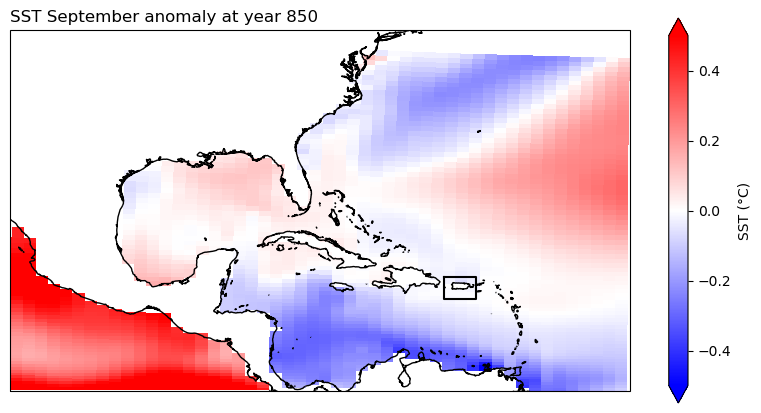

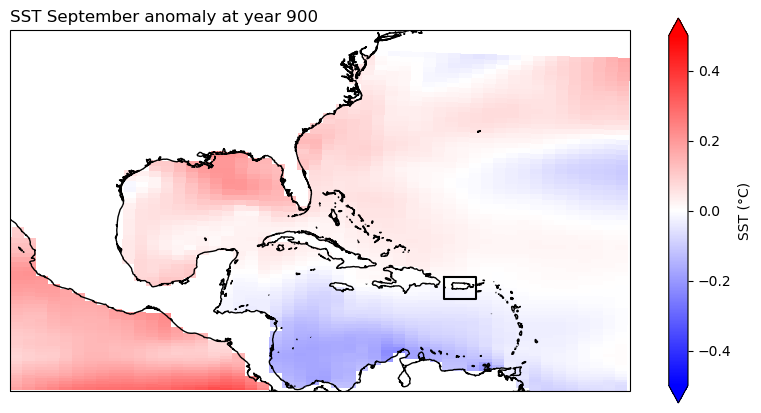

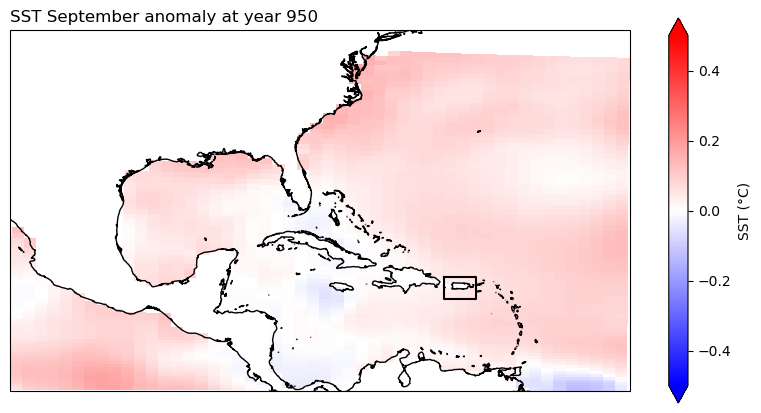

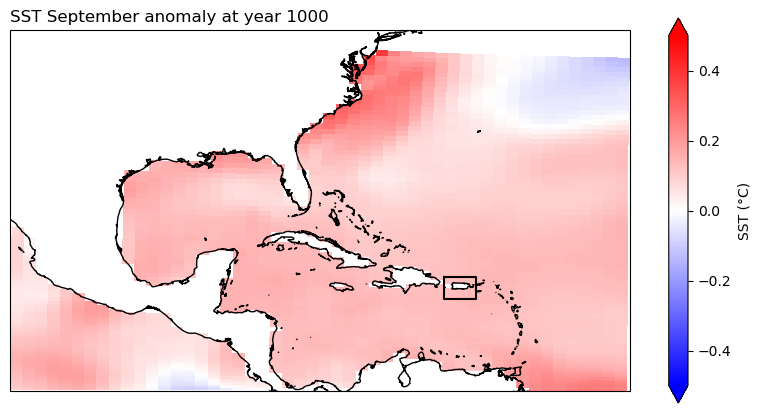

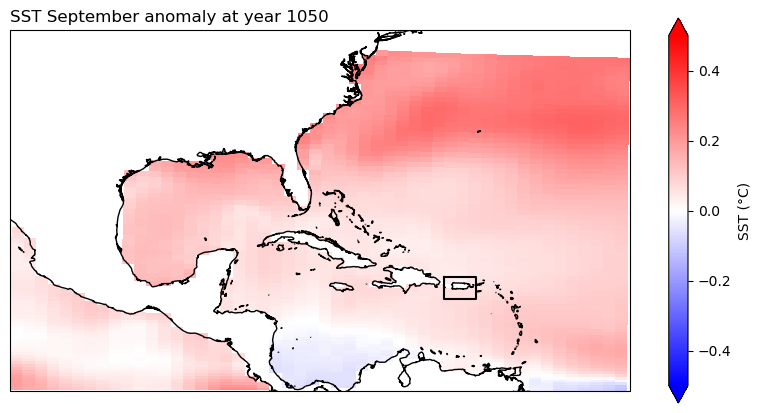

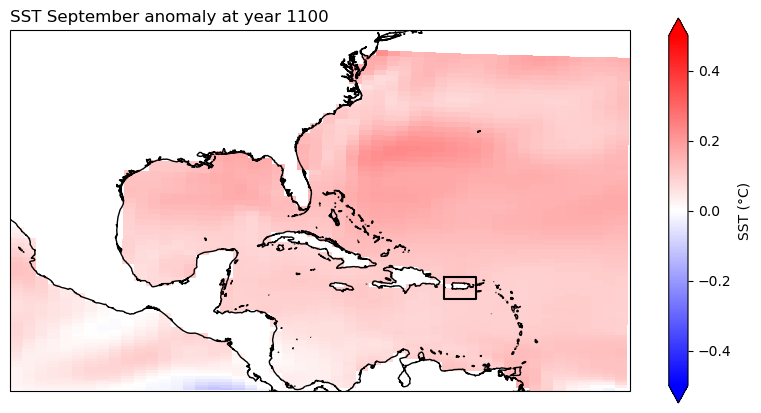

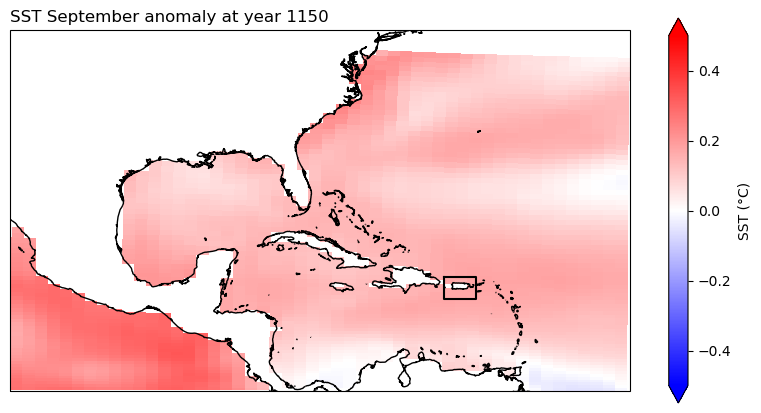

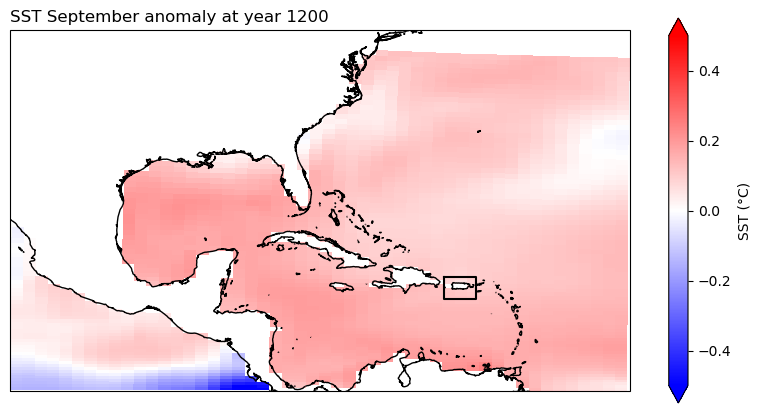

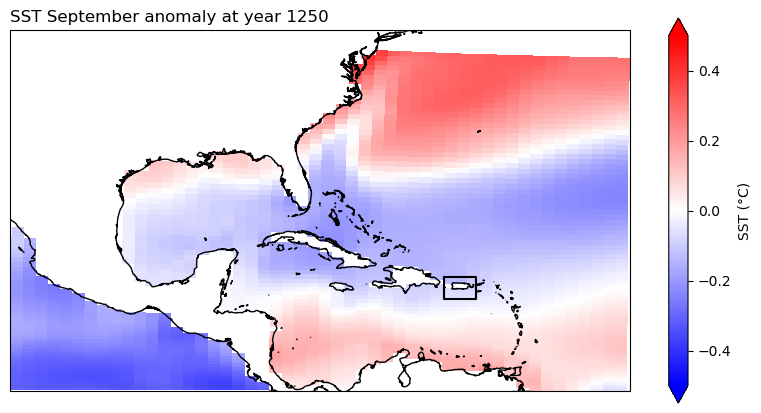

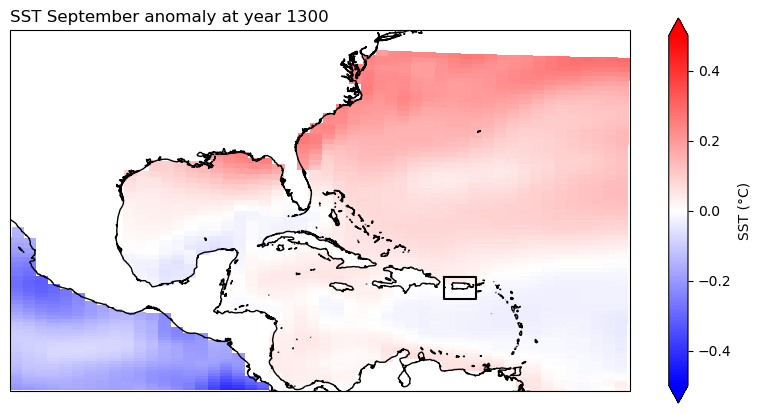

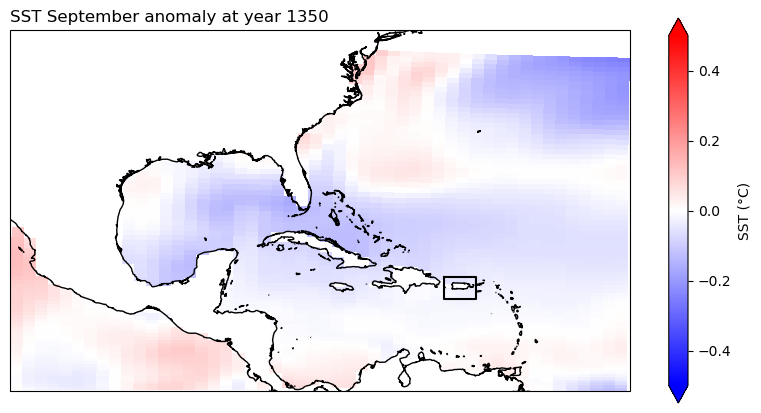

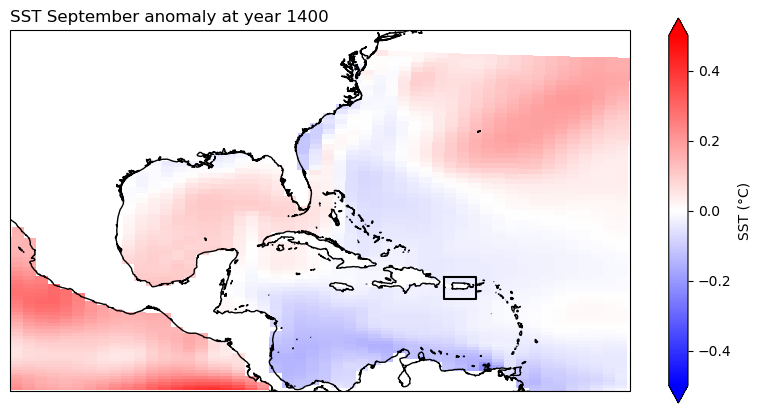

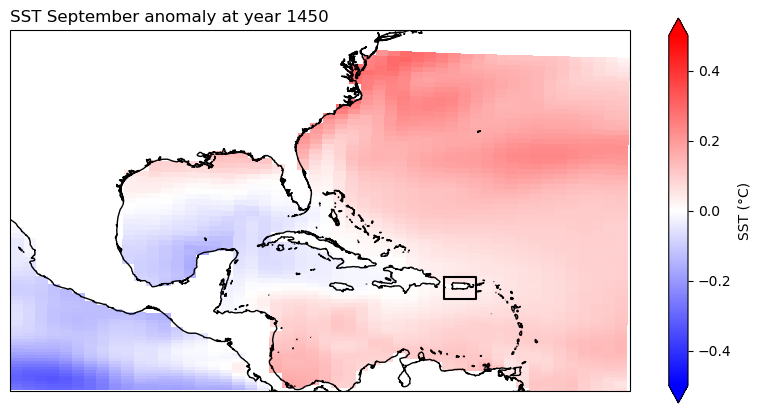

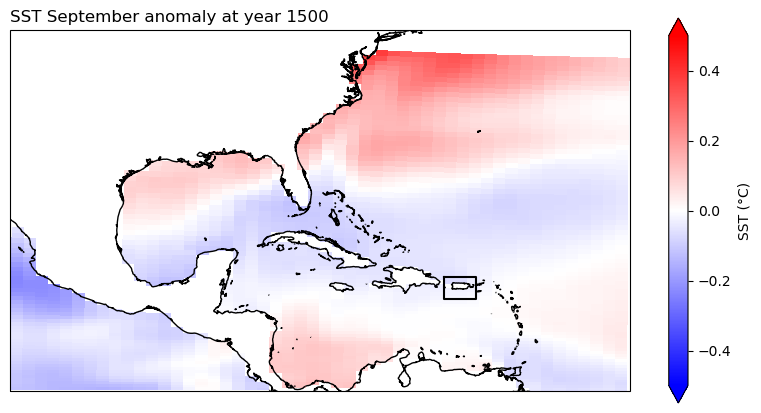

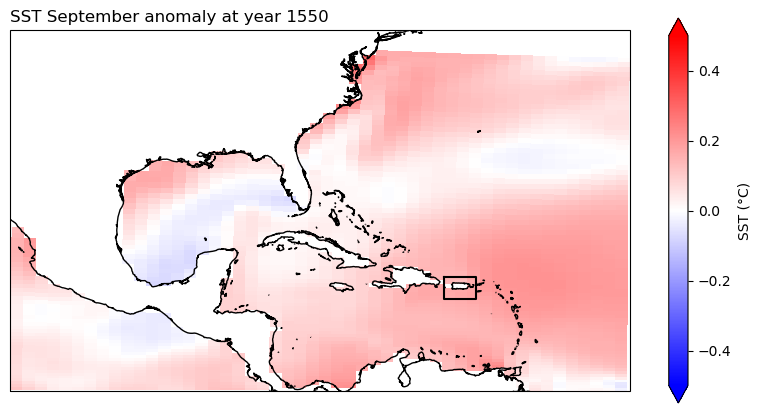

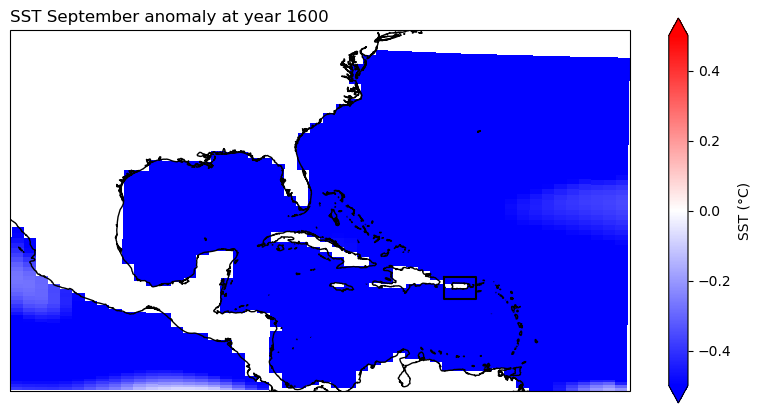

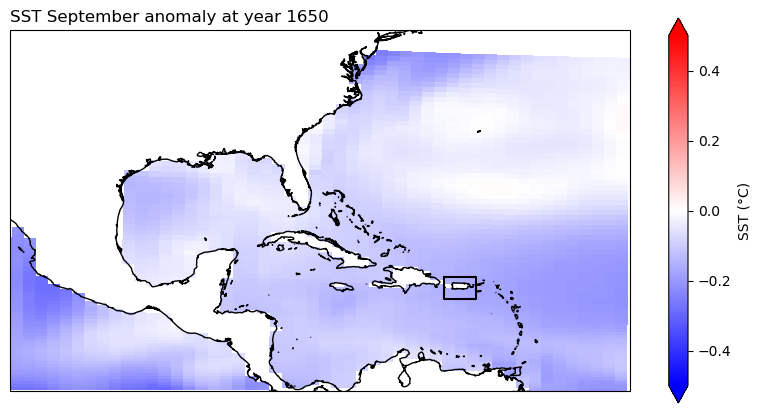

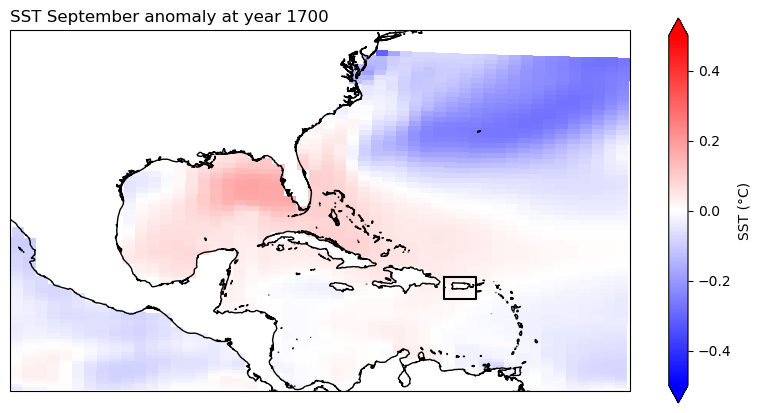

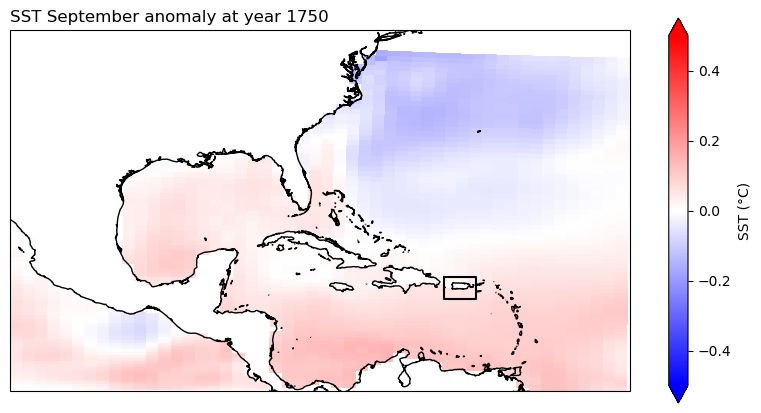

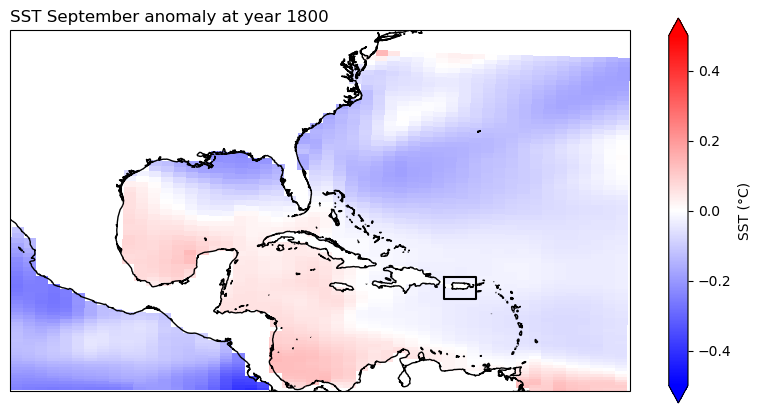

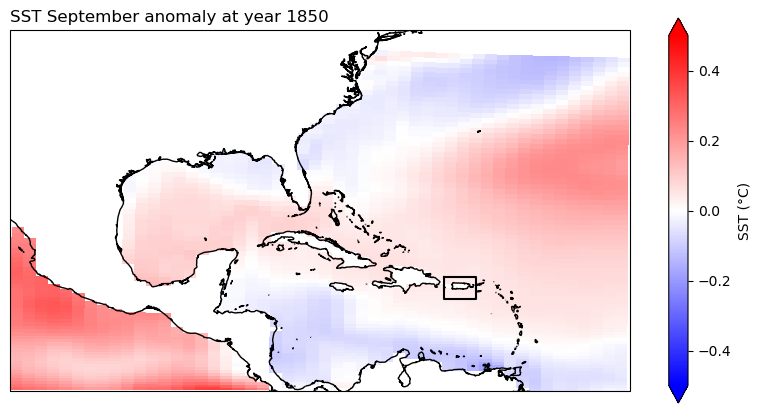

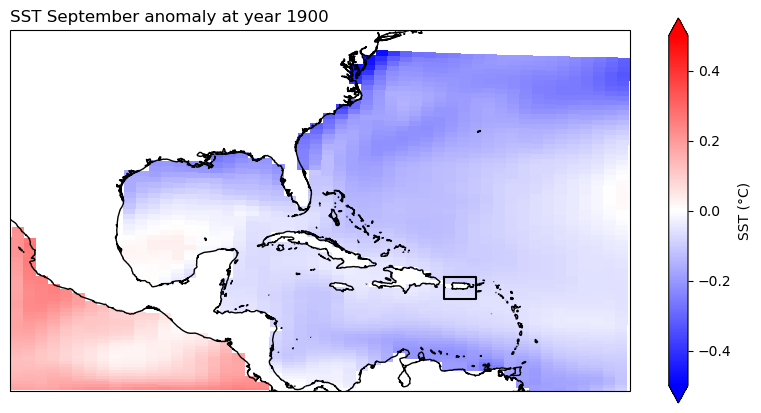

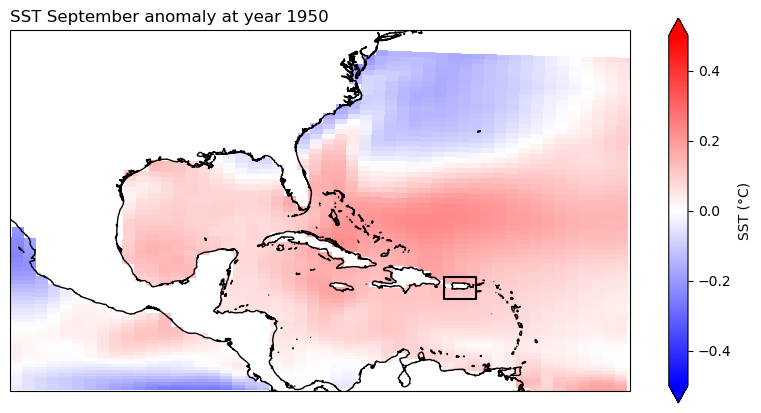

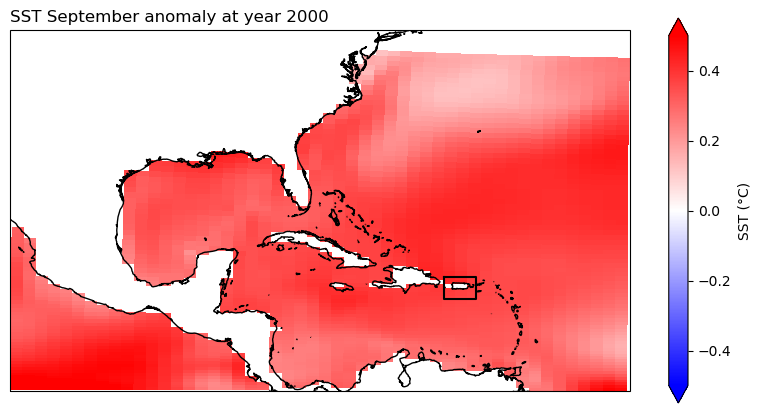

In [38]:
for year in np.arange(850,2001,50):

    fig = plt.figure(figsize=(10,5))

    ###############
    ax = fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())

    ax.set_title('SST September anomaly at year '+str(year), loc='left')

    #lon,lat,field = utils.adjust_pop_grid(lons, lats, ds_ann.SST.isel(time=ts))

    pc = ax.pcolormesh(lons, lats, SST_anoms_sept.sel(time=year).squeeze(),
                        transform=ccrs.PlateCarree(),cmap='bwr',
                       vmin=-0.5,vmax=0.5)
    ax.coastlines('10m',linewidth=1)

    lon_pts = [box1_lonmin,box1_lonmax,box1_lonmax,box1_lonmin,box1_lonmin]
    lat_pts = [box1_latmax,box1_latmax,box1_latmin,box1_latmin,box1_latmax]
    ax.plot(lon_pts, lat_pts, color="black", linewidth=1.5,transform=ccrs.PlateCarree())

    fig.colorbar(pc, label='SST (°C)',extend='both');